# Ứng dụng Machine Learning trên Kho dữ liệu Tuyển dụng CNTT (`IT_Job_Market_DW`)

**Đề tài:** *Xây dựng kho dữ liệu tuyển dụng ngành công nghệ thông tin nhằm hỗ trợ sinh viên lựa chọn kỹ năng và định hướng nghề nghiệp tại Việt Nam.*

Notebook này kết nối trực tiếp vào **SQL Server Data Warehouse (`IT_Job_Market_DW`)** để giải quyết 2 bài toán cốt lõi của đề tài:
1. **Bài toán 1 — Dự đoán những kỹ năng cần thiết cho sinh viên CNTT (Multi-Label Necessary Skill Prediction & Skill Gap Analysis)**: Dự báo xác suất các kỹ năng (`programming_language`, `framework`, `core_skill`, `foreign_language`) cần thiết cho từng vị trí nghề nghiệp và cấp bậc (`Intern`, `Fresher`, `Junior`...).
2. **Bài toán 2 — Định hướng nghề nghiệp từ hồ sơ kỹ năng của sinh viên (Career Orientation Classification & Feature Importance)**: Dự đoán nhóm ngành phù hợp (`Data/AI`, `Web/App`, `Software Engineer`, `Security`, `Embbed`) từ các kỹ năng sinh viên hiện có và xác định mức độ quan trọng của từng kỹ năng trên thị trường.

## 1. Kết nối SQL Server Data Warehouse (`IT_Job_Market_DW`) và Truy vấn Fact / Dimension

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import pyodbc
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, hamming_loss, roc_auc_score

CONN_STR = os.environ.get(
    "DW_SQLSERVER_CONNECTION_STRING",
    "DRIVER={ODBC Driver 18 for SQL Server};SERVER=DESKTOP-BNVB0UT;DATABASE=IT_Job_Market_DW;Trusted_Connection=yes;Encrypt=yes;TrustServerCertificate=yes"
)

with pyodbc.connect(CONN_STR) as conn:
    jobs = pd.read_sql("SELECT f.fact_job_key, f.job_id, f.source, f.title, f.company_name, f.observed_date_key, d.calendar_date FROM dw.fact_job f JOIN dw.dim_date d ON d.date_key = f.observed_date_key", conn)
    skills = pd.read_sql("SELECT f.fact_job_key, d.necessary_skill_key, d.skill_type, d.name AS skill_name, d.category, f.level_text, f.skill_mention_count FROM dw.fact_job_necessary_skill f JOIN dw.dim_necessary_skill d ON d.necessary_skill_key = f.necessary_skill_key", conn)
    roles = pd.read_sql("SELECT fact_job_key, role_key, name AS role_name, category AS role_category FROM dw.dim_role", conn)
    levels = pd.read_sql("SELECT fact_job_key, level_key, name AS level_name FROM dw.dim_level", conn)
    cities = pd.read_sql("SELECT fact_job_key, city_key, name AS city_name FROM dw.dim_city", conn)

print(f"Kết nối SQL Server DW (IT_Job_Market_DW) thành công!")
print(f"- Tổng số tin tuyển dụng (dw.fact_job): {len(jobs)} tin")
print(f"- Tổng số liên kết kỹ năng (dw.fact_job_necessary_skill): {len(skills)} dòng")
print(f"- Số kỹ năng duy nhất (dw.dim_necessary_skill): {skills['necessary_skill_key'].nunique()} kỹ năng")
print(f"- Tổng số bản ghi vị trí (dw.dim_role): {len(roles)} dòng ({roles['role_name'].nunique()} vị trí)")
print(f"- Tổng số bản ghi cấp bậc (dw.dim_level): {len(levels)} dòng")
print(f"- Tổng số bản ghi thành phố (dw.dim_city): {len(cities)} dòng")

Kết nối SQL Server DW (IT_Job_Market_DW) thành công!
- Tổng số tin tuyển dụng (dw.fact_job): 536 tin
- Tổng số liên kết kỹ năng (dw.fact_job_necessary_skill): 2807 dòng
- Số kỹ năng duy nhất (dw.dim_necessary_skill): 312 kỹ năng
- Tổng số bản ghi vị trí (dw.dim_role): 624 dòng (57 vị trí)
- Tổng số bản ghi cấp bậc (dw.dim_level): 549 dòng
- Tổng số bản ghi thành phố (dw.dim_city): 580 dòng


## 2. Khám phá Nhu cầu Thị trường từ Kho dữ liệu (Exploratory Data Analysis)

Top 15 kỹ năng có nhu cầu cao nhất trong DWH:
          skill_type         skill_name  job_count
    foreign_language            English        320
programming_language             Python        120
          core_skill                SQL        100
          core_skill                 AI         86
programming_language               Java         79
          core_skill                AWS         58
          core_skill                API         47
          core_skill             DevOps         46
          core_skill              Agile         44
          core_skill              Cloud         43
programming_language         JavaScript         41
          core_skill  Business Analysis         40
          core_skill              CI/CD         40
          core_skill              QA/QC         39
          core_skill Project Management         34


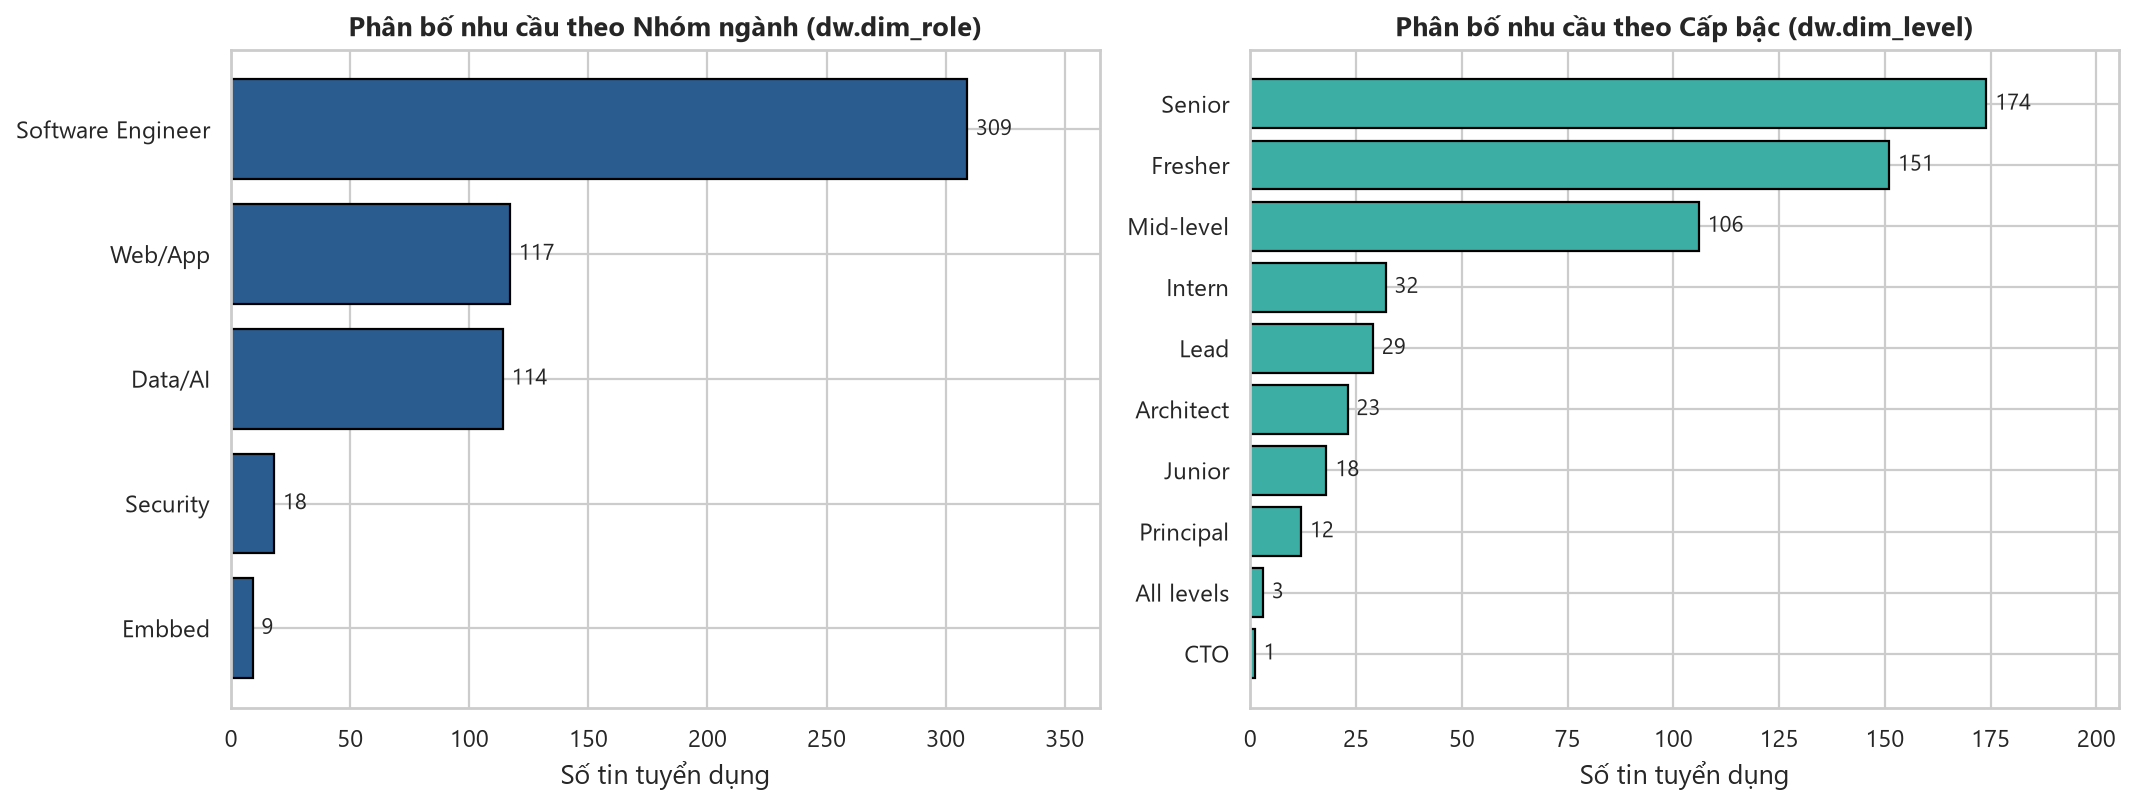

In [2]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

cat_counts = roles.groupby("role_category")["fact_job_key"].nunique().sort_values(ascending=True)
b1 = axes[0].barh(cat_counts.index, cat_counts.values, color="#2b5c8f", edgecolor="black")
axes[0].bar_label(b1, padding=4)
axes[0].set_title("Phân bố nhu cầu theo Nhóm ngành (dw.dim_role)", fontweight="bold")
axes[0].set_xlabel("Số tin tuyển dụng")

lvl_counts = levels.groupby("level_name")["fact_job_key"].nunique().sort_values(ascending=True)
b2 = axes[1].barh(lvl_counts.index, lvl_counts.values, color="#3caea3", edgecolor="black")
axes[1].bar_label(b2, padding=4)
axes[1].set_title("Phân bố nhu cầu theo Cấp bậc (dw.dim_level)", fontweight="bold")
axes[1].set_xlabel("Số tin tuyển dụng")
plt.tight_layout()
plt.show()

top_skills_summary = (
    skills.groupby(["skill_type", "skill_name"])["fact_job_key"]
    .nunique()
    .reset_index(name="job_count")
    .sort_values("job_count", ascending=False)
    .head(15)
)
print("Top 15 kỹ năng có nhu cầu cao nhất trong DWH:")
print(top_skills_summary.to_string(index=False))

## 3. Bài toán 1: Xây dựng Model Dự đoán những Kỹ năng cần thiết cho Sinh viên CNTT (Multi-Label Classification)

- **Đầu vào ($X$)**: Vị trí mục tiêu (`dw.dim_role`), Nhóm ngành (`role_category`), Cấp bậc (`dw.dim_level`: `Intern`, `Fresher`, `Junior`...), Thành phố (`dw.dim_city`).
- **Đầu ra ($Y$)**: Vector đa nhãn (Multi-Label) dự báo xác suất cần thiết của các kỹ năng chuẩn hóa trong `dw.dim_necessary_skill`.
- **Mô hình so sánh**: `OneVsRest(RandomForestClassifier)`, `OneVsRest(ExtraTreesClassifier)`, `OneVsRest(LogisticRegression)` đánh giá bằng 5-Fold Cross-Validation.

In [3]:
all_job_keys = sorted(jobs["fact_job_key"].unique())

role_pivot = roles.assign(val=1).pivot_table(index="fact_job_key", columns="role_name", values="val", aggfunc="max", fill_value=0).reindex(all_job_keys, fill_value=0)
role_pivot.columns = [f"role::{c}" for c in role_pivot.columns]

cat_pivot = roles.assign(val=1).pivot_table(index="fact_job_key", columns="role_category", values="val", aggfunc="max", fill_value=0).reindex(all_job_keys, fill_value=0)
cat_pivot.columns = [f"cat::{c}" for c in cat_pivot.columns]

level_pivot = levels.assign(val=1).pivot_table(index="fact_job_key", columns="level_name", values="val", aggfunc="max", fill_value=0).reindex(all_job_keys, fill_value=0)
level_pivot.columns = [f"level::{c}" for c in level_pivot.columns]

city_pivot = cities.assign(val=1).pivot_table(index="fact_job_key", columns="city_name", values="val", aggfunc="max", fill_value=0).reindex(all_job_keys, fill_value=0)
city_pivot.columns = [f"city::{c}" for c in city_pivot.columns]

X_context = pd.concat([role_pivot, cat_pivot, level_pivot, city_pivot], axis=1)

skills_c = skills.copy()
skills_c["label"] = skills_c["skill_type"] + "::" + skills_c["skill_name"]
skill_counts = skills_c.groupby("label")["fact_job_key"].nunique()
target_labels = skill_counts[skill_counts >= 12].sort_values(ascending=False).index.tolist()

Y_skills = (
    skills_c[skills_c["label"].isin(target_labels)]
    .assign(val=1)
    .pivot_table(index="fact_job_key", columns="label", values="val", aggfunc="max", fill_value=0)
    .reindex(index=all_job_keys, columns=target_labels, fill_value=0)
)

valid_mask = Y_skills.sum(axis=1) > 0
X_val = X_context.loc[valid_mask].values
Y_val = Y_skills.loc[valid_mask].values

def precision_at_k(y_true, y_prob, k=5):
    hits = []
    for i in range(len(y_true)):
        tset = set(np.where(y_true[i] == 1)[0])
        if not tset:
            continue
        topk = np.argsort(y_prob[i])[::-1][:k]
        hits.append(len(tset.intersection(topk)) / min(k, len(tset)))
    return float(np.mean(hits)) if hits else 0.0

t1_models = {
    "Random Forest (Multi-Label)": OneVsRestClassifier(RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, class_weight="balanced_subsample")),
    "Extra Trees (Multi-Label)": OneVsRestClassifier(ExtraTreesClassifier(n_estimators=200, max_depth=12, random_state=42, class_weight="balanced_subsample")),
    "Logistic Regression (Multi-Label)": OneVsRestClassifier(LogisticRegression(max_iter=1000, C=1.0, class_weight="balanced", random_state=42)),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
t1_results = []
for mname, clf in t1_models.items():
    yt_l, yp_l, ypr_l = [], [], []
    for tr, te in kf.split(X_val):
        clf.fit(X_val[tr], Y_val[tr])
        yp_l.append(clf.predict(X_val[te]))
        ypr_l.append(clf.predict_proba(X_val[te]))
        yt_l.append(Y_val[te])
    yt, yp, ypr = np.vstack(yt_l), np.vstack(yp_l), np.vstack(ypr_l)
    t1_results.append({
        "Model": mname,
        "Hamming_Accuracy": round(1.0 - hamming_loss(yt, yp), 4),
        "HitRate@5": round(precision_at_k(yt, ypr, 5), 4),
        "Micro_F1": round(f1_score(yt, yp, average="micro", zero_division=0), 4),
        "Macro_F1": round(f1_score(yt, yp, average="macro", zero_division=0), 4),
        "ROC_AUC_Micro": round(roc_auc_score(yt, ypr, average="micro"), 4),
    })

t1_df = pd.DataFrame(t1_results)
best_t1_clf = t1_models["Random Forest (Multi-Label)"]
best_t1_clf.fit(X_val, Y_val)

print(f"Kích thước tập huấn luyện Bài toán 1: X={X_val.shape}, Y={Y_val.shape} ({len(target_labels)} kỹ năng phổ biến)\n")
print("Kết quả đánh giá 5-Fold Cross-Validation (Bài toán 1 - Dự đoán kỹ năng cần thiết):")
print(t1_df.to_string(index=False))

Kích thước tập huấn luyện Bài toán 1: X=(524, 78), Y=(524, 57) (57 kỹ năng phổ biến)

Kết quả đánh giá 5-Fold Cross-Validation (Bài toán 1 - Dự đoán kỹ năng cần thiết):
                            Model  Hamming_Accuracy  HitRate@5  Micro_F1  Macro_F1  ROC_AUC_Micro
      Random Forest (Multi-Label)            0.9083     0.5083    0.3812    0.3039         0.8197
        Extra Trees (Multi-Label)            0.8885     0.4651    0.3574    0.3007         0.8063
Logistic Regression (Multi-Label)            0.8333     0.4429    0.3373    0.3175         0.8288


## 4. Ma trận Dự báo Kỹ năng cần thiết theo Vị trí Nghề nghiệp cho Sinh viên (Fresher / Junior)

Top 6 kỹ năng cần thiết nhất được mô hình dự báo cho từng vị trí (Fresher/Junior):
- Back-end Developer    : English (0.44), Go (0.42), Java (0.41), Microservices (0.39), SQL (0.36), Spring (0.33)
- Full-stack Developer  : English (0.55), React (0.50), TypeScript (0.50), Fullstack (0.47), Node.js (0.44), SQL (0.39)
- AI Engineer           : Python (0.78), AI (0.66), English (0.53), LLM (0.48), Machine Learning (0.41), API (0.30)
- Data Engineer         : Python (0.75), SQL (0.68), English (0.46), AWS (0.28), Oracle (0.20), Azure (0.18)
- Tester                : English (0.70), QA/QC (0.54), Automation Test (0.51), Agile (0.34), Scrum (0.28), Jira (0.26)
- Business Analyst      : Business Analysis (0.75), English (0.73), Agile (0.37), SQL (0.37), Figma (0.31), ERP (0.30)
- DevOps Engineer       : DevOps (0.92), AWS (0.63), English (0.62), Kubernetes (0.44), CI/CD (0.43), Cloud (0.42)
- Systems Engineer      : English (0.64), AWS (0.33), System Admin (0.32), DevOps (0.32), Linux (0.28), 

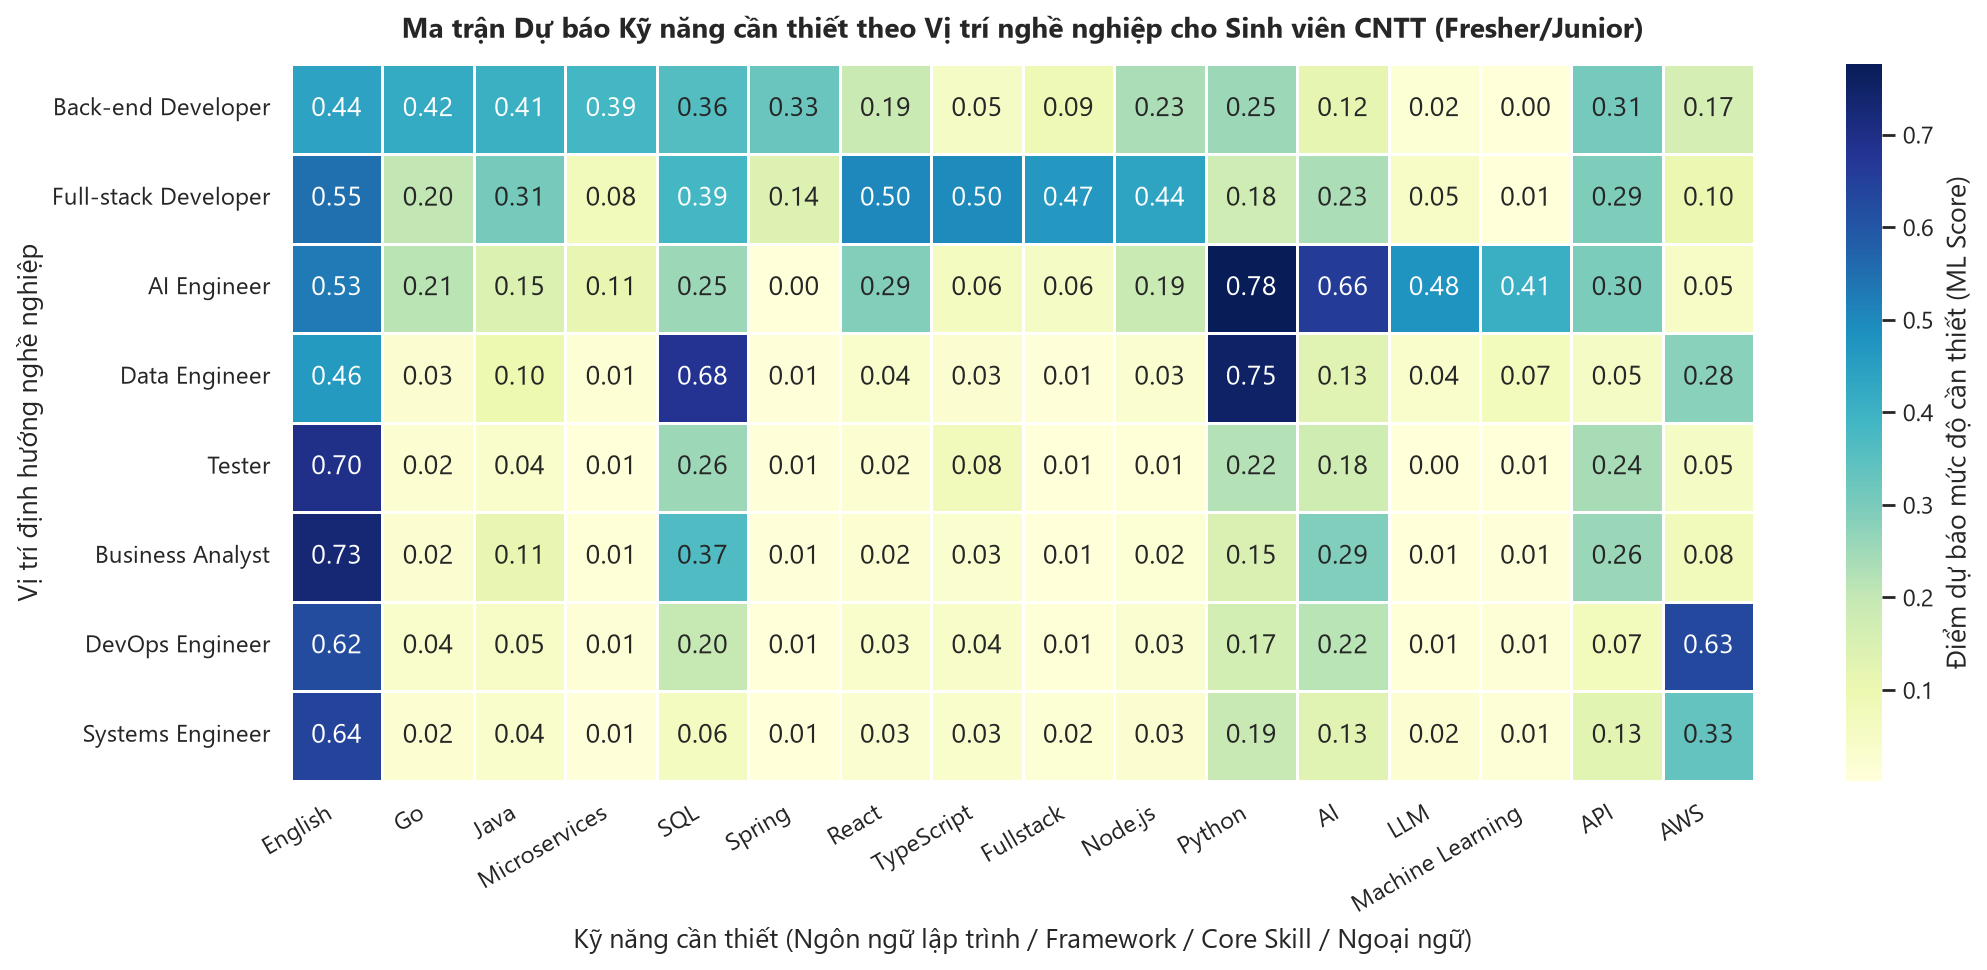

In [4]:
student_roles = [
    ("Back-end Developer", "Web/App"),
    ("Full-stack Developer", "Web/App"),
    ("AI Engineer", "Data/AI"),
    ("Data Engineer", "Data/AI"),
    ("Tester", "Software Engineer"),
    ("Business Analyst", "Software Engineer"),
    ("DevOps Engineer", "Software Engineer"),
    ("Systems Engineer", "Software Engineer"),
]

role_preds = {}
for rname, rcat in student_roles:
    xq = pd.Series(0.0, index=X_context.columns)
    for col_key in (f"role::{rname}", f"cat::{rcat}", "level::Fresher", "level::Junior", "city::Ho Chi Minh"):
        if col_key in xq.index:
            xq[col_key] = 1.0
    pr = best_t1_clf.predict_proba(xq.values.reshape(1, -1))[0]
    r_jkeys = roles[roles["role_name"] == rname]["fact_job_key"].unique()
    emp = Y_skills.loc[Y_skills.index.intersection(r_jkeys)].mean(axis=0).values if len(r_jkeys) else np.zeros_like(pr)
    score = 0.6 * pr + 0.4 * emp
    role_preds[rname] = {target_labels[idx].split("::", 1)[1]: round(float(score[idx]), 3) for idx in np.argsort(score)[::-1]}

union_skills = []
for rname, _ in student_roles:
    for sname in list(role_preds[rname].keys())[:6]:
        if sname not in union_skills:
            union_skills.append(sname)
union_skills = union_skills[:16]

heat_df = pd.DataFrame(0.0, index=[r for r, _ in student_roles], columns=union_skills)
for rname, _ in student_roles:
    for s in union_skills:
        heat_df.loc[rname, s] = role_preds[rname].get(s, 0.0)

fig, ax = plt.subplots(figsize=(13.5, 6.2))
sns.heatmap(heat_df, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.5, cbar_kws={"label": "Điểm dự báo mức độ cần thiết (ML Score)"}, ax=ax)
ax.set_title("Ma trận Dự báo Kỹ năng cần thiết theo Vị trí nghề nghiệp cho Sinh viên CNTT (Fresher/Junior)", fontweight="bold")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print("Top 6 kỹ năng cần thiết nhất được mô hình dự báo cho từng vị trí (Fresher/Junior):")
for rname, _ in student_roles:
    top6 = list(role_preds[rname].items())[:6]
    print(f"- {rname:22s}: " + ", ".join(f"{k} ({v:.2f})" for k, v in top6))

## 5. Bài toán 2: Định hướng Nhóm Nghề nghiệp từ Hồ sơ Kỹ năng của Sinh viên

- **Đầu vào ($X_{\text{skills}}$)**: Vector nhị phân biểu diễn các kỹ năng sinh viên hiện có.
- **Đầu ra ($y_{\text{career}}$)**: Nhóm nghề nghiệp (`Data/AI`, `Web/App`, `Software Engineer`, `Security`, `Embbed`).
- **Phân tích Feature Importance**: Trích xuất mức độ đóng góp (Gini Importance) từ Random Forest để xác định những kỹ năng nào đóng vai trò phân loại nghề nghiệp mạnh nhất.

Kích thước tập dữ liệu Bài toán 2: X=(535, 168) (168 đặc trưng kỹ năng), y=(535,)
Phân bố các nhóm ngành: {'Software Engineer': 284, 'Data/AI': 114, 'Web/App': 110, 'Security': 18, 'Embbed': 9}

Kết quả đánh giá 5-Fold Stratified Cross-Validation (Bài toán 2 - Định hướng nghề nghiệp):
                            Model  Accuracy  Weighted_F1  Weighted_Precision  Weighted_Recall  ROC_AUC_OvR
         Random Forest Classifier    0.7271       0.7308              0.7428           0.7271       0.8721
     Gradient Boosting Classifier    0.7533       0.7493              0.7476           0.7533       0.8793
Logistic Regression (Multinomial)    0.7364       0.7424              0.7564           0.7364       0.8922


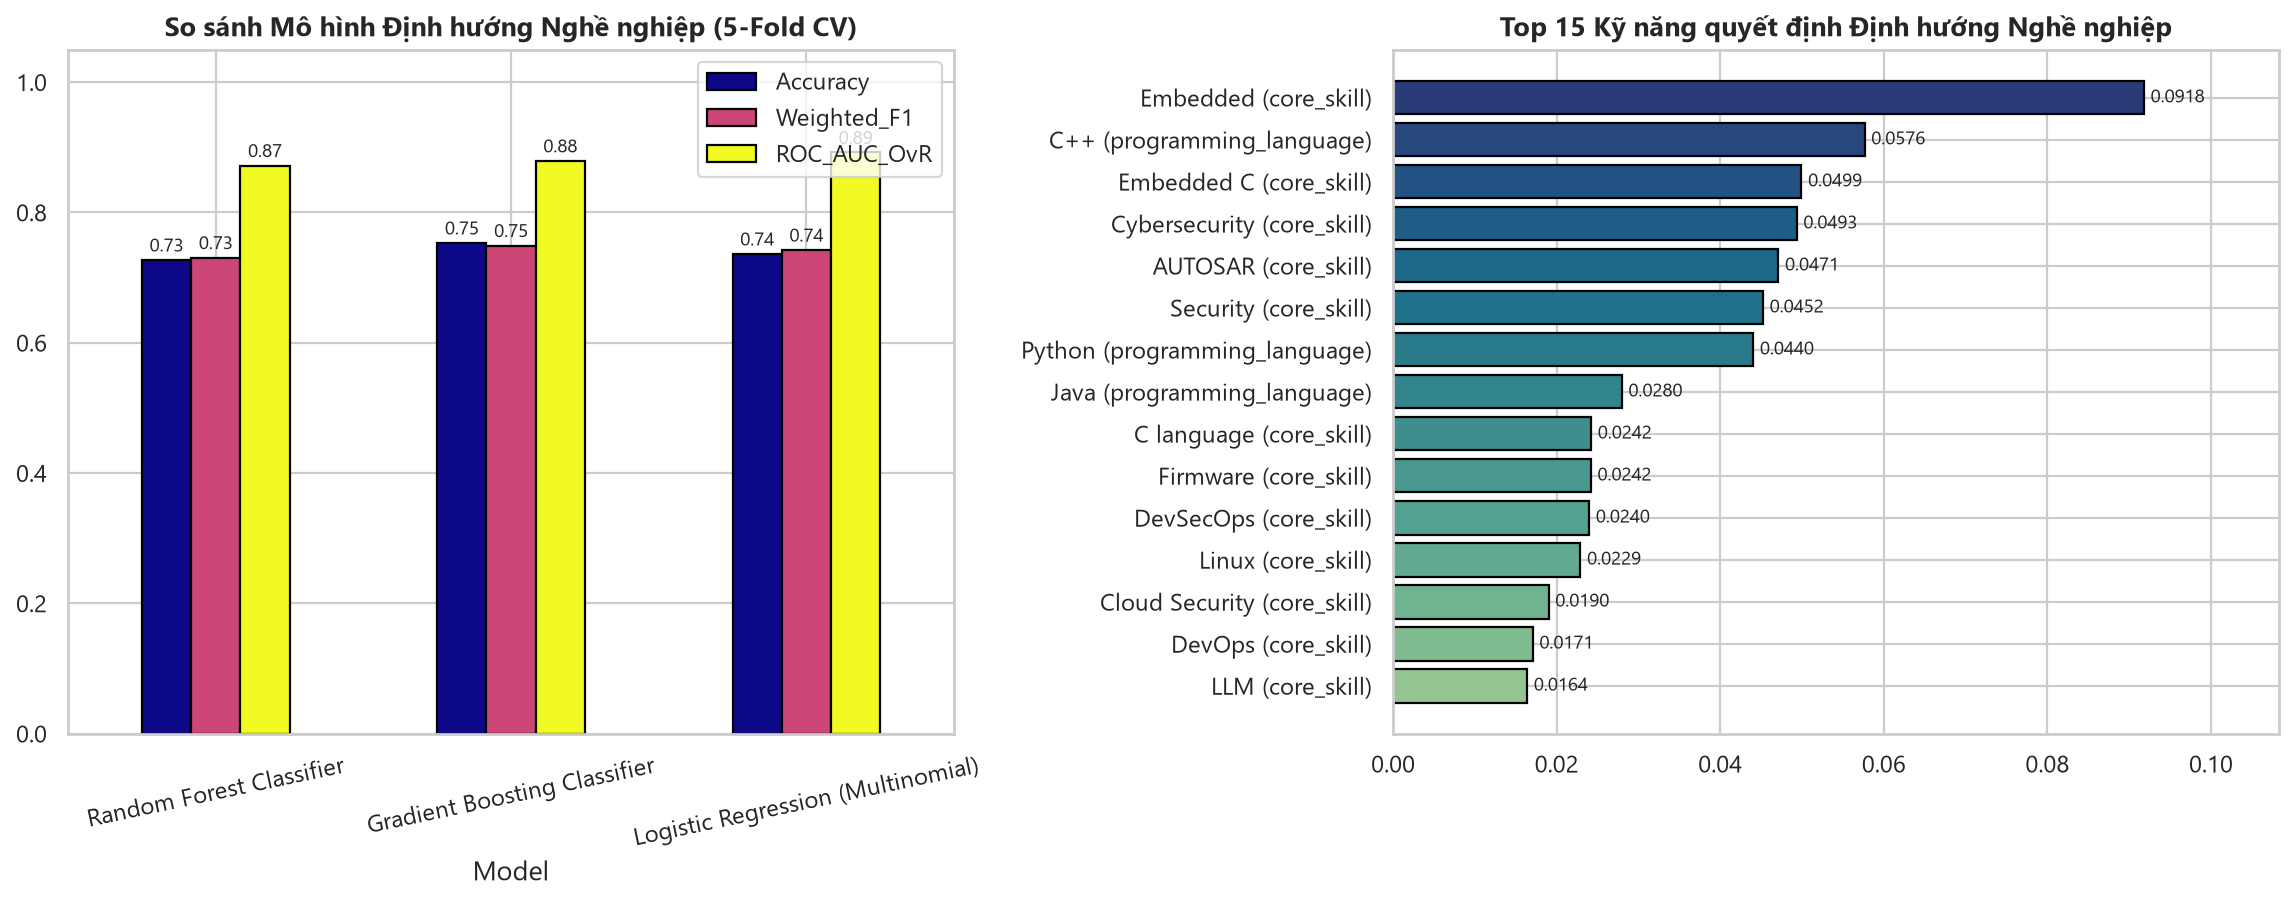

In [5]:
priority = {"Data/AI": 1, "Security": 2, "Embbed": 3, "Web/App": 4, "Software Engineer": 5}
roles_p = roles.copy()
roles_p["prio"] = roles_p["role_category"].map(lambda c: priority.get(c, 9))
primary_roles = roles_p.sort_values(["fact_job_key", "prio"]).drop_duplicates(subset=["fact_job_key"], keep="first").set_index("fact_job_key")

sel_feats = skill_counts[skill_counts >= 3].sort_values(ascending=False).index.tolist()
X_skills_df = skills_c[skills_c["label"].isin(sel_feats)].assign(val=1).pivot_table(index="fact_job_key", columns="label", values="val", aggfunc="max", fill_value=0)

common_keys = sorted(set(X_skills_df.index).intersection(set(primary_roles.index)))
X2_df = X_skills_df.loc[common_keys]
y2_s = primary_roles.loc[common_keys, "role_category"]

X2, y2 = X2_df.values, y2_s.values

t2_classifiers = {
    "Random Forest Classifier": RandomForestClassifier(n_estimators=300, max_depth=15, class_weight="balanced", random_state=42),
    "Gradient Boosting Classifier": GradientBoostingClassifier(n_estimators=150, max_depth=4, learning_rate=0.08, random_state=42),
    "Logistic Regression (Multinomial)": LogisticRegression(max_iter=1000, C=1.5, class_weight="balanced", random_state=42),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
t2_results = []
for mname, clf in t2_classifiers.items():
    yt_l, yp_l, ypr_l = [], [], []
    for tr, te in skf.split(X2, y2):
        clf.fit(X2[tr], y2[tr])
        yp_l.append(clf.predict(X2[te]))
        ypr_l.append(clf.predict_proba(X2[te]))
        yt_l.append(y2[te])
    yt, yp, ypr = np.concatenate(yt_l), np.concatenate(yp_l), np.vstack(ypr_l)
    t2_results.append({
        "Model": mname,
        "Accuracy": round(accuracy_score(yt, yp), 4),
        "Weighted_F1": round(f1_score(yt, yp, average="weighted", zero_division=0), 4),
        "Weighted_Precision": round(precision_score(yt, yp, average="weighted", zero_division=0), 4),
        "Weighted_Recall": round(recall_score(yt, yp, average="weighted", zero_division=0), 4),
        "ROC_AUC_OvR": round(roc_auc_score(yt, ypr, multi_class="ovr", average="weighted"), 4),
    })

t2_df = pd.DataFrame(t2_results)
rf_career = t2_classifiers["Random Forest Classifier"]
rf_career.fit(X2, y2)
importances = pd.Series(rf_career.feature_importances_, index=X2_df.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8))
t2_df.set_index("Model")[["Accuracy", "Weighted_F1", "ROC_AUC_OvR"]].plot(kind="bar", ax=axes[0], rot=12, colormap="plasma", edgecolor="black")
axes[0].set_title("So sánh Mô hình Định hướng Nghề nghiệp (5-Fold CV)", fontweight="bold")
axes[0].set_ylim(0, 1.05)

top15_imp = importances.head(15)[::-1]
clean_lbls = [f"{k.split('::', 1)[1]} ({k.split('::', 1)[0]})" for k in top15_imp.index]
bars = axes[1].barh(clean_lbls, top15_imp.values, color=sns.color_palette("crest", len(top15_imp)), edgecolor="black")
axes[1].bar_label(bars, fmt="%.4f", padding=3)
axes[1].set_title("Top 15 Kỹ năng quyết định Định hướng Nghề nghiệp", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Kích thước tập dữ liệu Bài toán 2: X={X2.shape} ({X2.shape[1]} đặc trưng kỹ năng), y={y2.shape}")
print(f"Phân bố các nhóm ngành: {y2_s.value_counts().to_dict()}\n")
print("Kết quả đánh giá 5-Fold Stratified Cross-Validation (Bài toán 2 - Định hướng nghề nghiệp):")
print(t2_df.to_string(index=False))

## 6. Ứng dụng Thực tế: Hệ thống Gợi ý Kỹ năng còn thiếu (Skill Gap) & Định hướng Nghề nghiệp cho Sinh viên

In [6]:
def recommend_student_pathway(name: str, target_role: str, target_level: str, target_city: str, known_skills: list[str]):
    known_set = {s.casefold() for s in known_skills}
    x_s = np.zeros((1, len(X2_df.columns)))
    for idx, col in enumerate(X2_df.columns):
        if col.split("::", 1)[1].casefold() in known_set:
            x_s[0, idx] = 1.0
    c_probs = rf_career.predict_proba(x_s)[0]
    c_rank = sorted(zip(rf_career.classes_, c_probs), key=lambda x: x[1], reverse=True)

    xq = pd.Series(0.0, index=X_context.columns)
    for ck in (f"role::{target_role}", f"level::{target_level}", f"city::{target_city}"):
        if ck in xq.index:
            xq[ck] = 1.0
    sp = best_t1_clf.predict_proba(xq.values.reshape(1, -1))[0]
    r_jkeys = roles[roles["role_name"] == target_role]["fact_job_key"].unique()
    emp = Y_skills.loc[Y_skills.index.intersection(r_jkeys)].mean(axis=0).values if len(r_jkeys) else np.zeros_like(sp)
    blended = 0.6 * sp + 0.4 * emp

    missing = []
    for idx in np.argsort(blended)[::-1]:
        st, sn = target_labels[idx].split("::", 1)
        if sn.casefold() not in known_set:
            missing.append(f"{sn} [{st}] ({blended[idx]:.2f})")
        if len(missing) >= 6:
            break

    top_careers = ", ".join(f"{c} ({p*100:.1f}%)" for c, p in c_rank[:3])
    print(f"=== {name} ===")
    print(f"  - Kỹ năng hiện có : {', '.join(known_skills)}")
    print(f"  - Mục tiêu        : {target_role} ({target_level}) tại {target_city}")
    print(f"  - Dự báo nhóm ngành phù hợp nhất (Model 2): {top_careers}")
    print(f"  - Top 6 Kỹ năng cần học thêm / Skill Gap (Model 1): {', '.join(missing)}\n")

recommend_student_pathway("Sinh viên A (Định hướng Data)", "Data Engineer", "Fresher", "Ho Chi Minh", ["Python", "SQL"])
recommend_student_pathway("Sinh viên B (Định hướng Web Backend)", "Back-end Developer", "Fresher", "Ho Chi Minh", ["Java", "SQL"])
recommend_student_pathway("Sinh viên C (Định hướng AI)", "AI Engineer", "Fresher", "Ha Noi", ["Python", "English"])

=== Sinh viên A (Định hướng Data) ===
  - Kỹ năng hiện có : Python, SQL
  - Mục tiêu        : Data Engineer (Fresher) tại Ho Chi Minh
  - Dự báo nhóm ngành phù hợp nhất (Model 2): Data/AI (66.2%), Software Engineer (16.5%), Web/App (13.9%)
  - Top 6 Kỹ năng cần học thêm / Skill Gap (Model 1): English [foreign_language] (0.51), AWS [core_skill] (0.31), C# [programming_language] (0.20), JavaScript [programming_language] (0.20), Database [core_skill] (0.19), AI [core_skill] (0.18)

=== Sinh viên B (Định hướng Web Backend) ===
  - Kỹ năng hiện có : Java, SQL
  - Mục tiêu        : Back-end Developer (Fresher) tại Ho Chi Minh
  - Dự báo nhóm ngành phù hợp nhất (Model 2): Web/App (54.8%), Software Engineer (21.0%), Data/AI (19.3%)
  - Top 6 Kỹ năng cần học thêm / Skill Gap (Model 1): English [foreign_language] (0.45), API [core_skill] (0.29), Python [programming_language] (0.28), Microservices [core_skill] (0.28), Go [programming_language] (0.27), Docker [core_skill] (0.26)

=== Sinh viên C (